In [2]:
from PIL import Image
import numpy as np
from pathlib import Path
from IPython.display import display

base_dir = Path('__file__').resolve().parent
data_path = base_dir / 'data'

## Show image dimention

In [4]:
import random 
random.seed(42)
test_data = data_path / 'Electrical-damage'
l = [entry.name for entry in test_data.iterdir()]
print(len(l))
l[0]

103


'Electrical (53).JPG'

/home/ovi/Desktop/Projects/Panel-Classifier/resources/data/Electrical-damage/Electrical (72).jpg


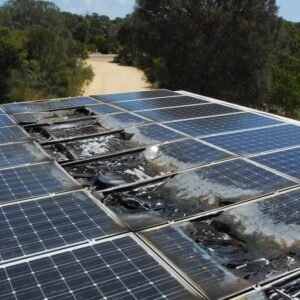

(300, 300)


In [5]:
any_image= test_data / l[np.random.randint(0, len(l))]
print(any_image)
img = Image.open(any_image)
display(img)
print(img.size)

# defining imag size


In [6]:
IMG_HI = 256
IMG_WI = 256
BATCH_SIZE = 32
SEED = 42

In [7]:
import tensorflow as tf

I0000 00:00:1792224251.029932   15457 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792224251.030283   15457 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792224251.059833   15457 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792224251.838448   15457 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [8]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_path,
    batch_size=BATCH_SIZE,
    image_size=(IMG_HI, IMG_WI),
    seed=SEED,
    subset='training',
    validation_split=0.2
)

Found 885 files belonging to 6 classes.
Using 708 files for training.


E0000 00:00:1792224258.821263   15457 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [ ]:
dir(train_dataset)

In [13]:
image, label = next(iter(train_dataset))
print(image.shape)
print(label)

(32, 256, 256, 3)
tf.Tensor([2 5 1 5 5 1 2 5 1 4 2 0 2 0 1 0 5 2 2 0 1 1 0 5 0 5 1 2 3 2 1 2], shape=(32,), dtype=int32)


In [14]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split =.2,
    subset= "validation",
    image_size= (IMG_HI, IMG_WI),
    seed= SEED,
    batch_size= BATCH_SIZE
)

Found 885 files belonging to 6 classes.
Using 177 files for validation.


In [16]:
class_names = train_dataset.class_names
num_classes = len(class_names)
print(num_classes)

6


In [17]:
class_names

['Bird-drop',
 'Clean',
 'Dusty',
 'Electrical-damage',
 'Physical-Damage',
 'Snow-Covered']

## Base Model 

In [19]:
model = tf.keras.models.Sequential([
    # Input: 256 x 256 x 3
    tf.keras.layers.Input(shape=(256, 256, 3)),

    # Normalize pixels from 0-255 to 0-1
    tf.keras.layers.Rescaling(1.0 / 255),

    # Block 1
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification head
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(6, activation="softmax")
])

In [20]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCH = 10


In [22]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCH)

Epoch 1/10


/home/ovi/Desktop/Projects/Panel-Classifier/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 ━━━━━━━━━━━━━━━━━━━━ 17s 700ms/step - accuracy: 0.2246 - loss: 1.7390 - val_accuracy: 0.3107 - val_loss: 1.7032
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 540ms/step - accuracy: 0.3602 - loss: 1.6350 - val_accuracy: 0.2994 - val_loss: 1.7293
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 589ms/step - accuracy: 0.3319 - loss: 1.6187 - val_accuracy: 0.4068 - val_loss: 1.5516
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 615ms/step - accuracy: 0.3630 - loss: 1.5340 - val_accuracy: 0.3672 - val_loss: 1.5605
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 611ms/step - accuracy: 0.3870 - loss: 1.5416 - val_accuracy: 0.3729 - val_loss: 1.6086
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 615ms/step - accuracy: 0.3927 - loss: 1.5094 - val_accuracy: 0.3785 - val_loss: 1.5066
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 628ms/step - accuracy: 0.3771 - loss: 1.4918 - val_accuracy: 0.4181 - val_loss: 1.4929
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 627ms/step - accuracy: 0.4082 - loss: 1.4846 - val_accuracy: 0.293

In [25]:
EPOCH = 100
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCH)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 637ms/step - accuracy: 0.6568 - loss: 0.9468 - val_accuracy: 0.5537 - val_loss: 1.1134
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 566ms/step - accuracy: 0.6596 - loss: 0.9177 - val_accuracy: 0.5932 - val_loss: 1.0613
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 549ms/step - accuracy: 0.6751 - loss: 0.8717 - val_accuracy: 0.5876 - val_loss: 1.0720
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 571ms/step - accuracy: 0.6596 - loss: 0.8980 - val_accuracy: 0.5706 - val_loss: 1.0670
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 574ms/step - accuracy: 0.6540 - loss: 0.9141 - val_accuracy: 0.5367 - val_loss: 1.1197
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 584ms/step - accuracy: 0.6638 - loss: 0.9106 - val_accuracy: 0.5819 - val_loss: 1.1448
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 596ms/step - accuracy: 0.6695 - loss: 0.9098 - val_accuracy: 0.6215 - val_loss: 1.0784
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 594ms/step - accuracy: 0.6751 - loss: 0.8892 - 

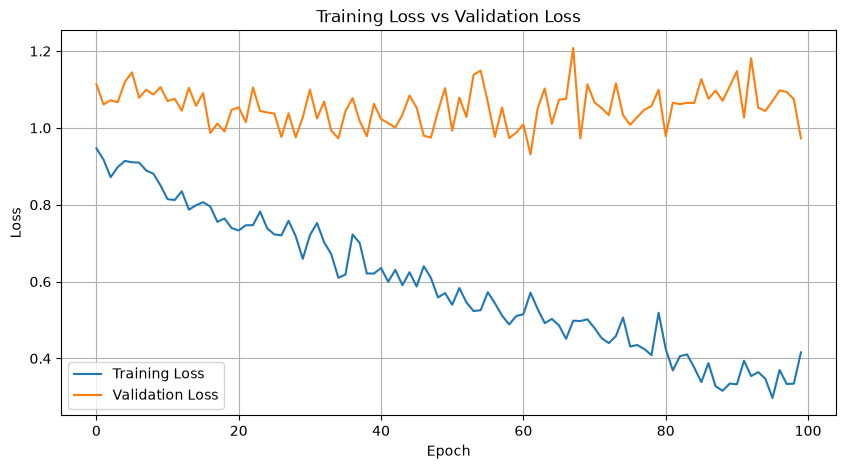

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

# data augmentation

In [27]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

In [33]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(256, 256, 3)),

    data_augmentation,

    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
        ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(6, activation="softmax")


])

In [34]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## early stopping

In [35]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [36]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 780ms/step - accuracy: 0.2811 - loss: 2.2480 - val_accuracy: 0.1921 - val_loss: 2.1865
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 818ms/step - accuracy: 0.3192 - loss: 1.6420 - val_accuracy: 0.3559 - val_loss: 1.5821
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 804ms/step - accuracy: 0.3489 - loss: 1.5968 - val_accuracy: 0.2994 - val_loss: 1.6660
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 826ms/step - accuracy: 0.3701 - loss: 1.5763 - val_accuracy: 0.2768 - val_loss: 1.7962
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 832ms/step - accuracy: 0.4124 - loss: 1.5145 - val_accuracy: 0.4011 - val_loss: 1.5513
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 820ms/step - accuracy: 0.4054 - loss: 1.5195 - val_accuracy: 0.4068 - val_loss: 1.5114
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 843ms/step - accuracy: 0.3912 - loss: 1.5147 - val_accuracy: 0.3277 - val_loss: 1.6022
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 834ms/step - accuracy: 0.4393 - loss: 1.4665 - val_accu

## Transfer Learning

